# Electronics review sentiment analysis

**ISY503 Assessment 3 | CNN training and evaluation**

This notebook trains and evaluates a binary sentiment classifier for Amazon Electronics reviews. The team prepared three separate data files with `text` and `label` columns (`0` = negative, `1` = positive). Data cleaning and train/validation/test splitting were performed separately by the data preparation team member.

The CNN uses `TextVectorization`, an embedding layer, `Conv1D`, max pooling, dropout and a sigmoid output. Its vocabulary is built **only from the training split**.

**How to run**
- **From the repository:** open `notebooks/train_and_evaluate.ipynb` with Jupyter and run all cells. The notebook finds the repository's `data/` directory.
- **Standalone in Google Colab:** run all cells, then select the team data ZIP when prompted. Only the input CSVs are uploaded; no personal Google Drive path is required.

Training creates a **new** model under `outputs/`. It does not overwrite `model/sentiment_model.keras`, the already selected v8 application model. Final results at the end are reported separately from the previous selected run.

## 1. Load the data

Check the size of each split, label balance, and column names before training.

In [ ]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
import io
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score, log_loss,
)
from IPython.display import display

SEED = 42
MAX_WORDS = 10000
SEQUENCE_LENGTH = 256
BATCH_SIZE = 32
MAX_EPOCHS = 15
DROPOUT_RATE = 0.50

keras.utils.set_random_seed(SEED)

# The repository has data/ beside notebooks/.
project_dir = next(
    (folder for folder in (Path.cwd(), Path.cwd().parent)
     if (folder / 'data' / 'train.csv').is_file()),
    Path.cwd(),
)
data_dir = project_dir / 'data'

# A standalone Colab notebook needs the team data ZIP once.
if not (data_dir / 'train.csv').is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            'Cannot find data/train.csv. Start Jupyter from the repository '
            'or run this notebook in Colab and upload the team data ZIP.'
        ) from exc
    print('Select 03_TEAM_DATA_AUDITED_v1.zip')
    uploaded = files.upload()
    archive_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if len(archive_names) != 1:
        raise ValueError('Please upload one ZIP containing train.csv, val.csv, and test.csv.')
    data_dir = Path.cwd() / 'data'
    data_dir.mkdir(exist_ok=True)
    with ZipFile(io.BytesIO(uploaded[archive_names[0]])) as archive:
        for filename in ('train.csv', 'val.csv', 'test.csv'):
            matches = [name for name in archive.namelist()
                       if Path(name).name == filename]
            if len(matches) != 1:
                raise ValueError(f'Expected one {filename} in the ZIP.')
            (data_dir / filename).write_bytes(archive.read(matches[0]))

train_df = pd.read_csv(data_dir / 'train.csv')
val_df = pd.read_csv(data_dir / 'val.csv')
test_df = pd.read_csv(data_dir / 'test.csv')
frames = {'Train': train_df, 'Validation': val_df, 'Test': test_df}

for split, frame in frames.items():
    if list(frame.columns) != ['text', 'label']:
        raise ValueError(f'{split}: expected text and label columns.')
    if frame.isna().any().any() or not frame['text'].astype(str).str.strip().all():
        raise ValueError(f'{split}: empty or missing values found.')
    if not frame['label'].isin([0, 1]).all():
        raise ValueError(f'{split}: labels must be 0 or 1.')

expected_sizes = (1572, 195, 198)
if tuple(len(frame) for frame in frames.values()) != expected_sizes:
    raise ValueError('Use the audited team dataset (1572 / 195 / 198 rows).')

overview = pd.DataFrame([
    {'Split': name, 'Reviews': len(frame),
     'Negative (0)': int((frame['label'] == 0).sum()),
     'Positive (1)': int((frame['label'] == 1).sum())}
    for name, frame in frames.items()
])
display(overview)


## 2. Encode the reviews

`TextVectorization` learns its vocabulary from training reviews. Reviews are padded or truncated to 256 tokens. Datasets are batched for training and evaluation.

In [ ]:
def make_dataset(frame, shuffle=False):
    texts = np.asarray(frame['text'].astype(str).tolist(), dtype=str)
    labels = frame['label'].to_numpy(dtype='int32')
    dataset = tf.data.Dataset.from_tensor_slices((texts, labels))
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=SEED)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

vectorizer = keras.layers.TextVectorization(
    max_tokens=MAX_WORDS,
    standardize='lower_and_strip_punctuation',
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH,
    name='text_vectorization',
)
vectorizer.adapt(np.asarray(train_df['text'].astype(str).tolist(), dtype=str))
print('Vocabulary size:', len(vectorizer.get_vocabulary()))
print('Input length:', SEQUENCE_LENGTH, 'tokens | Batch size:', BATCH_SIZE)


## 3. Build and train the CNN

The model predicts the probability of a positive review. Early stopping monitors validation loss and restores the best observed weights.

In [ ]:
keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(), dtype=tf.string, name='review_text')
x = vectorizer(inputs)
x = keras.layers.Embedding(input_dim=MAX_WORDS, output_dim=64)(x)
x = keras.layers.Conv1D(filters=64, kernel_size=3, activation='relu')(x)
x = keras.layers.GlobalMaxPooling1D()(x)
x = keras.layers.Dense(32, activation='relu')(x)
x = keras.layers.Dropout(DROPOUT_RATE)(x)
outputs = keras.layers.Dense(1, activation='sigmoid', name='positive_probability')(x)

model = keras.Model(inputs, outputs, name='electronics_sentiment_cnn')
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=[keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True
    )],
    verbose=2,
)


## 4. Training history

The table shows performance for each completed epoch. The plots make it easier to see convergence and possible overfitting.

In [ ]:
output_dir = project_dir / 'outputs'
output_dir.mkdir(exist_ok=True)

epoch_table = pd.DataFrame(history.history)
epoch_table.insert(0, 'epoch', np.arange(1, len(epoch_table) + 1))
display(epoch_table.round(4))
epoch_table.to_csv(output_dir / 'training_history.csv', index=False)

best_epoch = int(epoch_table['val_loss'].idxmin()) + 1
print(f'Best validation-loss epoch: {best_epoch} of {len(epoch_table)}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, key, title in ((axes[0], 'loss', 'Loss'),
                       (axes[1], 'accuracy', 'Accuracy')):
    ax.plot(epoch_table['epoch'], epoch_table[key], marker='o', label='Training')
    ax.plot(epoch_table['epoch'], epoch_table['val_' + key], marker='o', label='Validation')
    ax.set(xlabel='Epoch', title=title)
    ax.legend()
plt.tight_layout()
fig.savefig(output_dir / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Evaluate the model

Evaluate the restored model on validation and test data. The test set has already been inspected in earlier team experiments, so the numbers are **not** presented as results from a fully untouched final holdout.

In [ ]:
val_true = val_df['label'].to_numpy(dtype=int)
val_prob = model.predict(val_ds, verbose=0).reshape(-1)
val_pred = (val_prob >= 0.5).astype(int)

test_true = test_df['label'].to_numpy(dtype=int)
test_prob = model.predict(test_ds, verbose=0).reshape(-1)
test_pred = (test_prob >= 0.5).astype(int)

summary = pd.DataFrame([
    {'Split': 'Validation', 'Accuracy': accuracy_score(val_true, val_pred),
     'Macro F1': f1_score(val_true, val_pred, average='macro'),
     'Log loss': log_loss(val_true, val_prob, labels=[0, 1])},
    {'Split': 'Test', 'Accuracy': accuracy_score(test_true, test_pred),
     'Macro F1': f1_score(test_true, test_pred, average='macro'),
     'Log loss': log_loss(test_true, test_prob, labels=[0, 1])},
])
display(summary.round(4))
summary.to_csv(output_dir / 'evaluation_summary.csv', index=False)

report = classification_report(
    test_true, test_pred, labels=[0, 1],
    target_names=['Negative', 'Positive'], zero_division=0,
)
print('Test classification report:\n' + report)
(output_dir / 'classification_report.txt').write_text(report, encoding='utf-8')

cm = confusion_matrix(test_true, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive']).plot(
    ax=ax, cmap='Blues', values_format='d', colorbar=False,
)
ax.set_title('Test confusion matrix')
fig.tight_layout()
fig.savefig(output_dir / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Review incorrect predictions

Look at the errors rather than relying on accuracy alone. Short excerpts are shown below, and the complete error table is saved for the report.

In [ ]:
errors = test_df.loc[test_true != test_pred, ['text', 'label']].copy()
errors['predicted_label'] = test_pred[test_true != test_pred]
errors['positive_probability'] = test_prob[test_true != test_pred]
errors.to_csv(output_dir / 'misclassified_reviews.csv', index=False)

print(f'Incorrect predictions: {len(errors)} / {len(test_df)}')
preview = errors.head(6).copy()
preview['text'] = preview['text'].str.slice(0, 160)
display(preview)


## 7. Save the retrained model and results

This section stores the **current notebook run**, not the archived selected v8 model. A new `outputs/retrained_sentiment_model.keras` is written, then reloaded to verify that it produces the same predictions.

In [ ]:
model_file = output_dir / 'retrained_sentiment_model.keras'
model.save(model_file)
reloaded = keras.models.load_model(model_file, compile=False)

examples = [
    'These headphones sound great and are very comfortable.',
    'The charger broke after a day. Very disappointing.',
]
original_probs = model.predict(tf.constant(examples), verbose=0).reshape(-1)
reloaded_probs = reloaded.predict(tf.constant(examples), verbose=0).reshape(-1)
assert np.allclose(original_probs, reloaded_probs, atol=1e-6)
for review, probability in zip(examples, reloaded_probs):
    sentiment = 'Positive review' if probability >= 0.5 else 'Negative review'
    print(f'{sentiment} ({probability:.3f}) | {review}')

metadata = {
    'dataset': 'TEAM Electronics',
    'train_rows': len(train_df), 'validation_rows': len(val_df), 'test_rows': len(test_df),
    'sequence_length': SEQUENCE_LENGTH, 'dropout': DROPOUT_RATE,
    'best_epoch': best_epoch, 'epochs_run': len(epoch_table),
    'validation_accuracy': float(summary.iloc[0]['Accuracy']),
    'test_accuracy': float(summary.iloc[1]['Accuracy']),
    'test_macro_f1': float(summary.iloc[1]['Macro F1']),
    'tensorflow_version': tf.__version__,
    'python_version': platform.python_version(),
    'note': 'Fresh run; not the archived selected v8 model. Prior test set was inspected.',
}
(output_dir / 'run_info.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

# Save all results as one ZIP so a standalone Colab run is not lost on reset.
archive_path = project_dir / 'training_run_outputs.zip'
with ZipFile(archive_path, 'w', ZIP_DEFLATED) as archive:
    for file_path in output_dir.iterdir():
        if file_path.is_file():
            archive.write(file_path, arcname='outputs/' + file_path.name)
print('Saved run artifacts:', archive_path)
print('Test accuracy for THIS training run: {:.2%}'.format(summary.iloc[1]['Accuracy']))

if 'google.colab' in __import__('sys').modules:
    from google.colab import files
    files.download(str(archive_path))


## Selected application model: recorded v8 results

These figures and metrics come from the **previously completed v8 validation-selected experiment**, not from the fresh training run above. They are included as a reference for the team's selected application model, which remains in `model/sentiment_model.keras`.

| Metric | Selected v8 model |
|---|---:|
| Validation accuracy | 84.62% |
| Validation log loss | 0.3916 |
| Test accuracy | **90.40% (179/198)** |
| Test macro F1 | **0.9039** |
| Test errors | 19/198 |

**Interpretation:** Performance improved over the earlier model on the validation metrics used for model selection. The test set had already been examined during development, so the test result must be described as exploratory rather than completely independent. The results, saved model, original training graphs, and error records are archived in `results/` and the original v8 experiment files.

### Recorded v8 epoch history (from the original training log)

| Epoch | Train accuracy | Train loss | Validation accuracy | Validation loss |
|---:|---:|---:|---:|---:|
| 1 | 0.5318 | 0.6916 | 0.6513 | 0.6857 |
| 2 | 0.7226 | 0.6505 | 0.7179 | 0.6368 |
| 3 | 0.7716 | 0.5252 | 0.6923 | 0.5582 |
| 4 | 0.8823 | 0.3607 | 0.8103 | 0.4450 |
| 5 | 0.9510 | 0.2040 | 0.8462 | 0.3916 |
| 6 | 0.9835 | 0.0996 | 0.8359 | 0.4059 |
| 7 | 0.9949 | 0.0537 | 0.8359 | 0.4195 |
| 8 | 0.9968 | 0.0318 | 0.8615 | 0.4559 |

*EarlyStopping restored the weights from epoch 5 (lowest validation loss). The full precision validation log loss for this saved model is 0.391613.*

### Recorded test classification report

| Label | Precision | Recall | F1 | Support |
|---|---:|---:|---:|---:|
| Negative | 0.92 | 0.88 | 0.90 | 98 |
| Positive | 0.89 | 0.93 | 0.91 | 100 |


**Recorded v8 training curves**

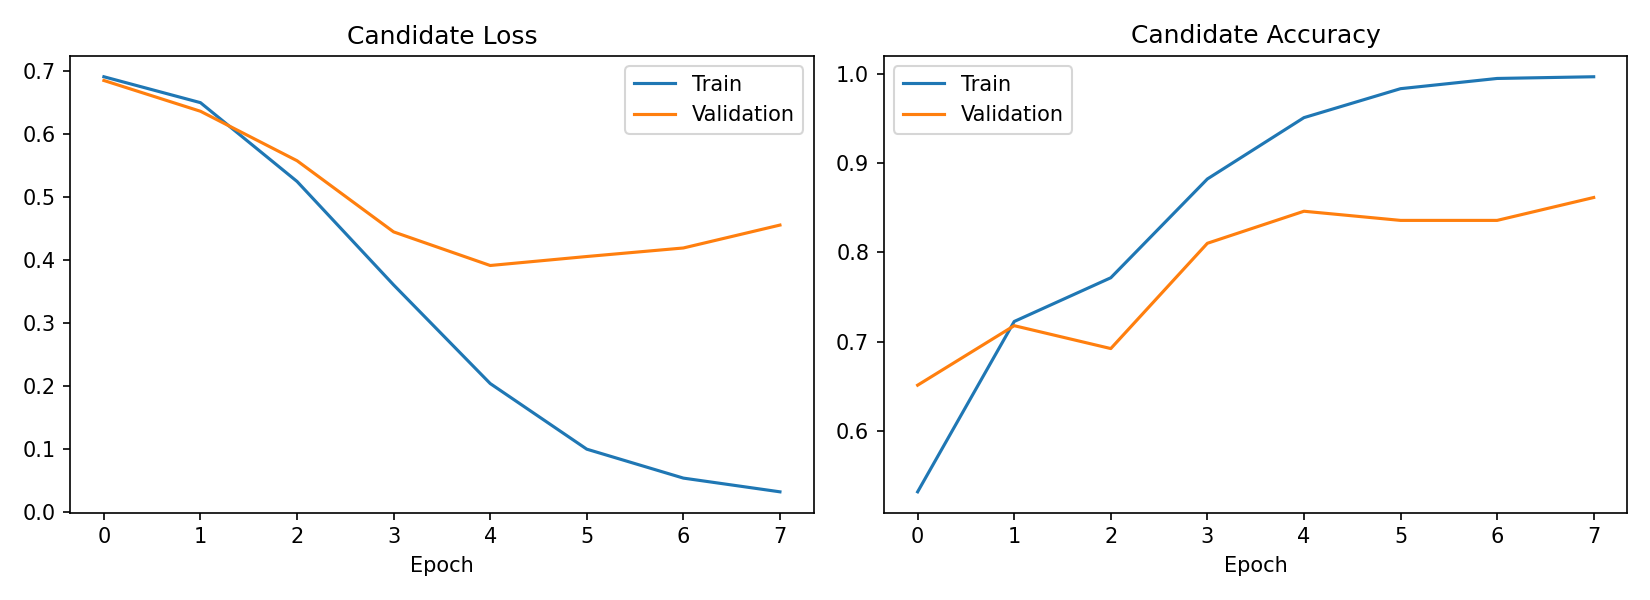

**Recorded v8 test confusion matrix**

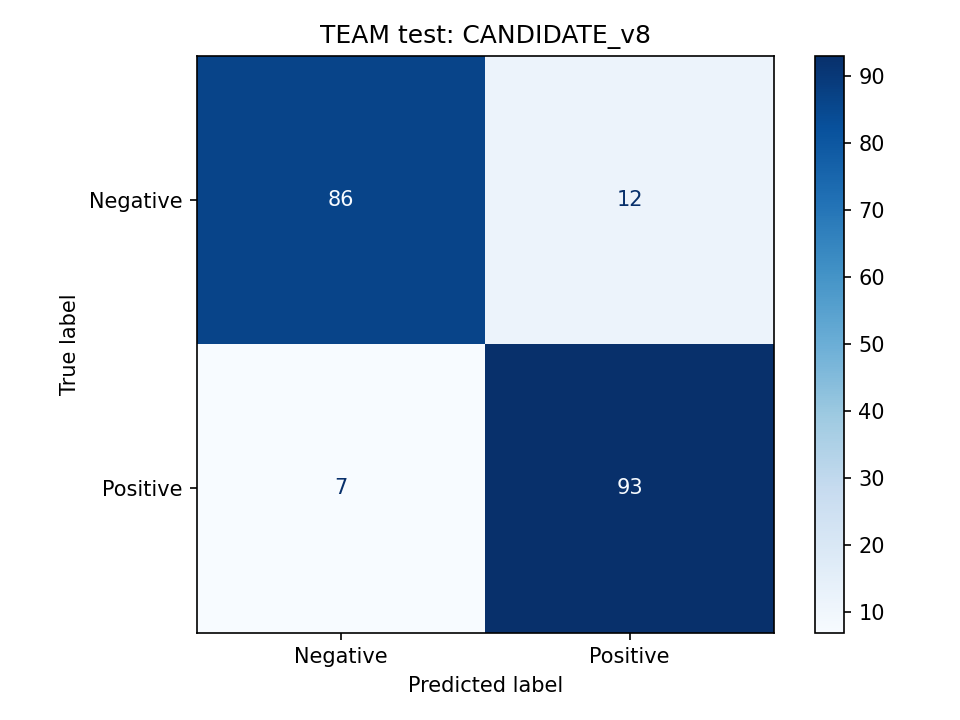